# Trading simulation and error analysis

Vector simulations are approximate. The exact simulation iterates day by day with reinvestment of gains, a concurrent position limit, stop loss on the daily low and entry at the next session open.

In [1]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config, features, models, pipeline, simulation
from src import analysis

In [2]:
preds = pd.read_parquet(config.PREDICTIONS_PATH)
thresholds = pipeline.load_thresholds()
with_sims = simulation.add_vector_simulations(preds, thresholds)
simulation.vector_summary(with_sims)

,prediction,strategy,trades,precision,avg_net_return_per_trade,approx_cagr,approx_sharpe,approx_max_drawdown
0,pred_dt,sim1,61392,0.325515,0.001446,-0.064656,-1.168250,-0.340098
1,pred_dt,sim2,3690,0.325203,0.000176,0.000584,-0.456060,-0.308923
2,pred_dt,sim3,2820,0.320922,-0.000837,-0.037669,-1.003716,-0.349426
3,pred_rf,sim1,84999,0.329027,0.004749,-0.016620,-0.718422,-0.289884
4,pred_rf,sim2,3690,0.388889,0.004923,0.262475,1.029934,-0.351521
5,pred_rf,sim3,2820,0.395745,0.005633,0.228041,0.997849,-0.229040
6,pred_xgb,sim1,78457,0.329136,0.006938,-0.004331,-0.602131,-0.283152
7,pred_xgb,sim2,3690,0.362602,0.000255,-0.001412,-0.313723,-0.403282
8,pred_xgb,sim3,2820,0.368794,0.000574,0.012813,-0.315152,-0.286386
9,pred_ens,sim1,85892,0.330054,0.005848,-0.008181,-0.642771,-0.283944


## Exact simulations versus benchmarks

In [3]:
table, vector = pipeline.step_simulate()
table[["key", "cagr", "sharpe", "max_drawdown", "trades", "win_rate"]]

                               key    cagr  sharpe  max_drawdown  trades  win_rate
        pred_dt__sim1_equal_weight -0.0298 -0.3489       -0.4149  1479.0    0.4638
       pred_dt__sim2_stop_weighted -0.2041 -1.3176       -0.6215  1398.0    0.4435
 pred_dt__sim3_regime_concentrated -0.0896 -0.7381       -0.4028   597.0    0.4539
        pred_rf__sim1_equal_weight -0.0208 -0.1145       -0.4258  1479.0    0.4936
       pred_rf__sim2_stop_weighted -0.0593 -0.2566       -0.5812  1486.0    0.4711
 pred_rf__sim3_regime_concentrated  0.0596  0.1173       -0.4678   622.0    0.4759
       pred_xgb__sim1_equal_weight -0.1291 -0.4743       -0.5018  1479.0    0.4503
      pred_xgb__sim2_stop_weighted -0.2295 -0.8746       -0.6478  1513.0    0.4263
pred_xgb__sim3_regime_concentrated -0.1491 -0.5721       -0.5568   610.0    0.4475
       pred_ens__sim1_equal_weight -0.0833 -0.3141       -0.5413  1479.0    0.4767
      pred_ens__sim2_stop_weighted -0.0676 -0.2739       -0.5610  1506.0    0.4602
pred

Best strategy by CAGR: pred_rf__sim3_regime_concentrated


,key,cagr,sharpe,max_drawdown,trades,win_rate
0,pred_dt__sim1_equal_weight,-0.029763,-0.348933,-0.414891,1479.0,0.463827
1,pred_dt__sim2_stop_weighted,-0.204148,-1.317641,-0.621486,1398.0,0.443491
2,pred_dt__sim3_regime_concentrated,-0.089631,-0.738125,-0.402813,597.0,0.453936
3,pred_rf__sim1_equal_weight,-0.020752,-0.114459,-0.425821,1479.0,0.493577
4,pred_rf__sim2_stop_weighted,-0.059281,-0.256594,-0.581177,1486.0,0.471063
5,pred_rf__sim3_regime_concentrated,0.059647,0.117319,-0.467835,622.0,0.475884
6,pred_xgb__sim1_equal_weight,-0.129147,-0.474299,-0.501765,1479.0,0.450304
7,pred_xgb__sim2_stop_weighted,-0.229454,-0.874618,-0.647818,1513.0,0.426305
8,pred_xgb__sim3_regime_concentrated,-0.149133,-0.572149,-0.556784,610.0,0.447541
9,pred_ens__sim1_equal_weight,-0.083295,-0.314139,-0.541286,1479.0,0.476673


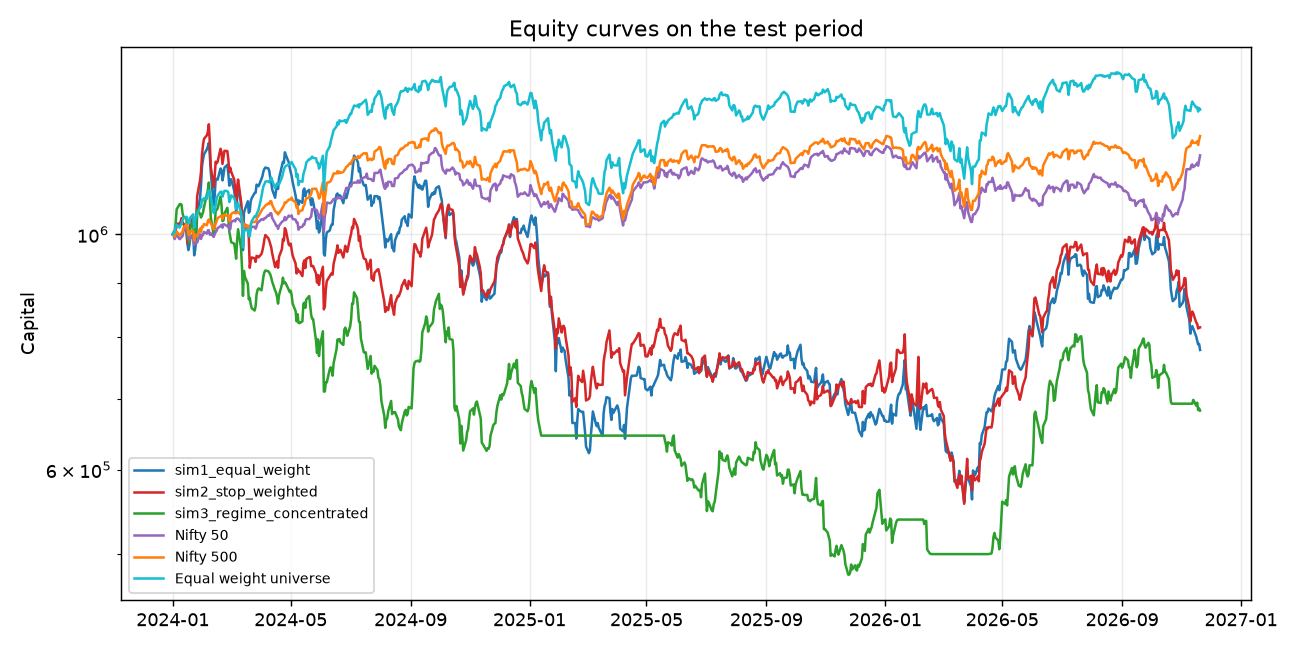

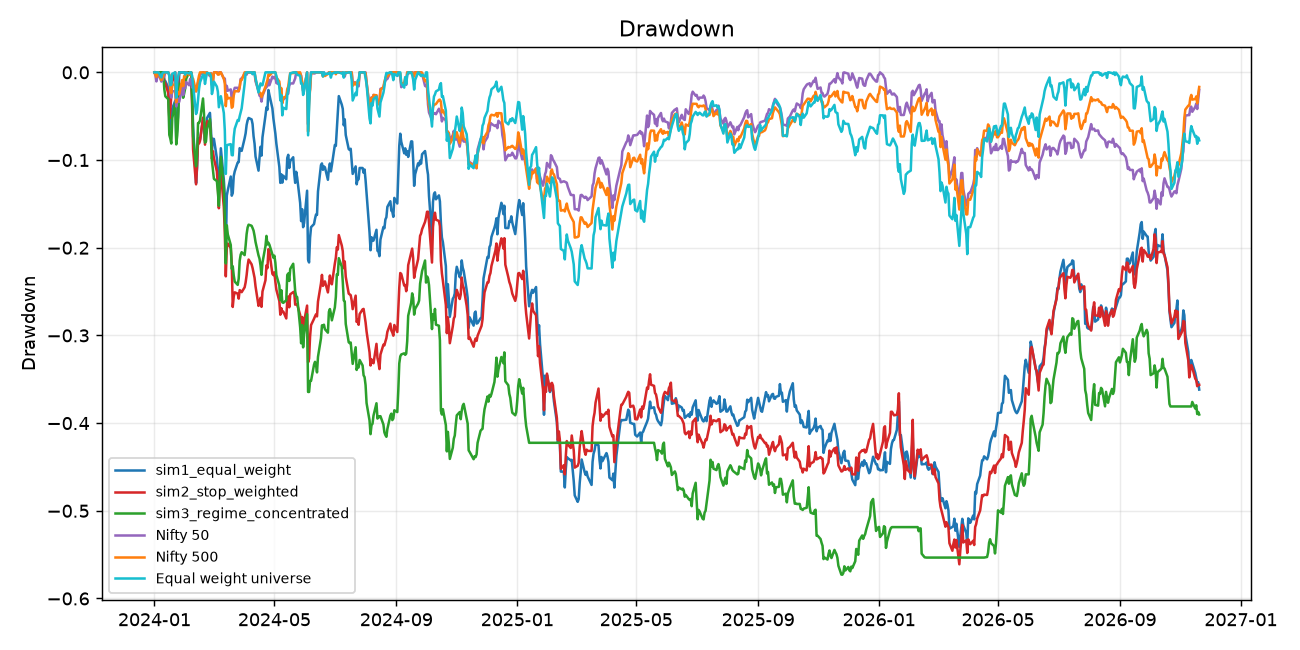

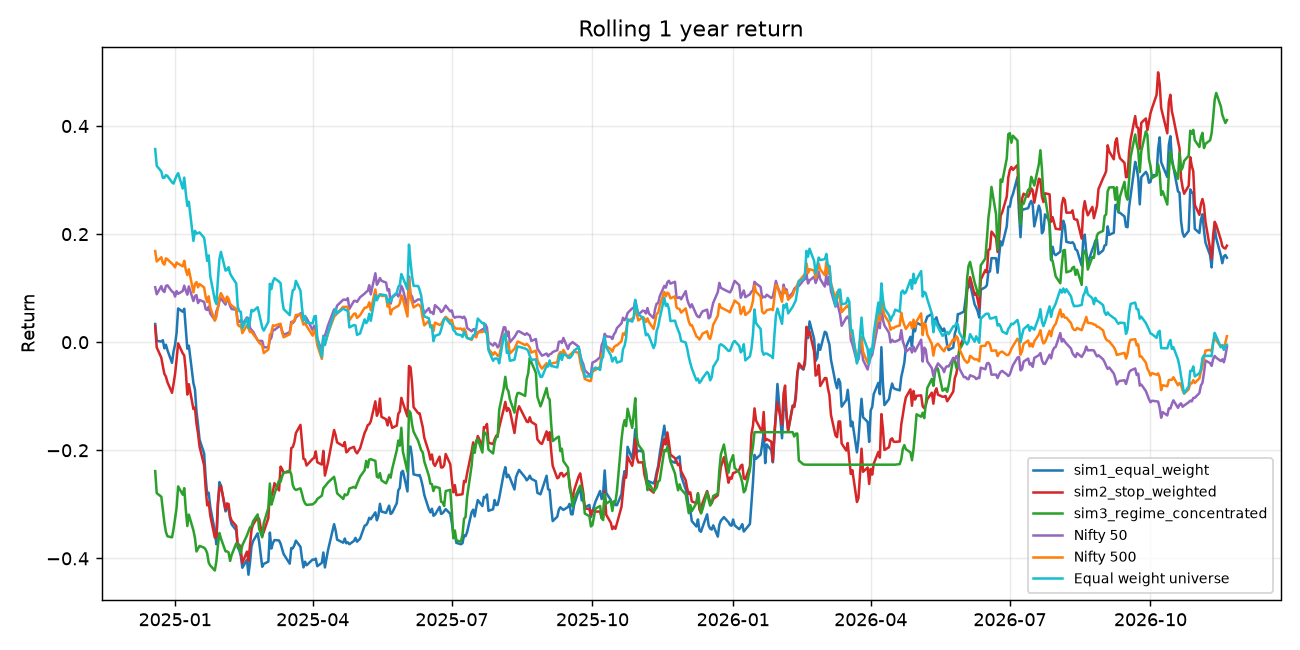

In [4]:
for name in ("equity_curves.png", "equity_drawdown.png", "equity_rolling_1y.png"):
    display(Image(str(config.REPORT_DIR / name)))

## Where do predictions fail

In [5]:
tables, gaps, findings = analysis.run_analysis(preds, thresholds)
display(Markdown(findings))

# Findings for pred_ens at threshold 0.3005

Signals on the test period: 85892. Precision 0.330. Average forward return 0.0088.
By year: best lift 1.23 at 2025, worst lift 1.17 at 2026.
By regime: best lift 1.25 at healthy, worst lift 1.08 at weak.
By volatility_bucket: best lift 1.17 at q1_low, worst lift 1.12 at q4_high.
By liquidity_bucket: best lift 1.25 at q1_low, worst lift 1.16 at q4_high.
By sector (50 or more signals): best lift 1.42 at Construction, worst lift 0.76 at Diversified.

Features that differ most between false positives and true positives:
- cs_rank_vol_21: standardized gap -0.08
- intraday_range: standardized gap -0.07
- atr_pct_14: standardized gap -0.07
- vol_63: standardized gap -0.05
- dist_52w_low: standardized gap -0.05
- ret_126: standardized gap -0.05
- vol_21: standardized gap -0.04
- vix: standardized gap 0.04


In [6]:
tables["sector"].sort_values("lift", ascending=False).head(10)

,sector,observations,base_rate,signals,precision,avg_forward_return,lift,avg_net_return
3,Construction,8062,0.245845,1756,0.350228,0.017958,1.424590,0.014958
15,Power,10342,0.259331,1957,0.344916,0.013485,1.330022,0.010485
18,Telecommunication,6247,0.262366,1251,0.340528,0.017854,1.297911,0.014854
8,Fast Moving Consumer Goods,17583,0.268100,2525,0.346535,0.011113,1.292558,0.008113
12,Media Entertainment & Publication,2286,0.258968,418,0.332536,0.007445,1.284083,0.004445
19,Textiles,2767,0.259125,282,0.326241,0.009241,1.259009,0.006241
20,Unknown,166823,0.268704,30556,0.335646,0.006744,1.249129,0.003744
16,Realty,7601,0.287462,1852,0.356371,0.009572,1.239716,0.006572
13,Metals & Mining,12452,0.286139,2561,0.348301,0.015403,1.217247,0.012403
1,Capital Goods,40314,0.297639,10704,0.356222,0.013005,1.196827,0.010005


In [7]:
gaps.head(15)

,feature,mean_false_positive,mean_true_positive,standardized_gap,abs_gap
0,cs_rank_vol_21,0.663431,0.683055,-0.079292,0.079292
1,intraday_range,0.046909,0.048985,-0.074344,0.074344
2,atr_pct_14,0.048031,0.049115,-0.068830,0.068830
3,vol_63,0.030661,0.031163,-0.052495,0.052495
4,dist_52w_low,0.980247,1.029633,-0.051661,0.051661
5,ret_126,0.336168,0.363492,-0.047553,0.047553
6,vol_21,0.031690,0.032238,-0.044647,0.044647
7,vix,16.565380,16.389441,0.044571,0.044571
8,breadth_sma50,0.480248,0.470084,0.044152,0.044152
9,vol_5,0.028707,0.029503,-0.043907,0.043907
